# N152 — Predict improvement on a persistent rolling image bank

Authorized 5 November 2026. This notebook tests the proposed rolling-bank objective
against sustained replay. N151 already predicted a randomly resampled 64-image
bank's next loss, but combined it with current-image loss and did not maintain
persistent per-image loss histories. Here both controllers use the same full FIFO
bank, and differ only in their objective's current-loss weight.

## Question and three arms

1. Fixed quarter-rate replay, the stronger N150/N151 baseline.
2. Bank-only controller: normalized predicted bank reconstruction loss plus inverse
   normalized predicted bank RankMe.
3. Mixed controller: 50/50 normalized current and bank reconstruction losses, plus
   the identical inverse normalized predicted bank RankMe.

For predicted relative H1 changes d_c, d_b, d_r, minimize

    J_w = w*(1+d_c) + (1-w)*(1+d_b) + 1/(1+d_r)

Bank-only uses w=0; Mixed uses w=.5. All prediction features, update rules, seeds,
exploration, rank checks, residual margins, and action choices are otherwise equal.
Current-image loss is still measured and forecast in the bank-only arm; its explicit
objective weight is zero. This retains the same predictor architecture and isolates
the objective change. Per-image histories are saved for diagnostics; the predictor
still receives the same 17 aggregate/image/history features as N151, not a new
high-dimensional per-image model.

The unchanged menu is {quarter-rate replay, 1/16-rate replay, quarter-rate
current-five}. Replay uses .5 first current-view loss plus .5 mean loss on four
distinct past images; current-five replaces those images with four current-image
views. One Adam step, five gradient images, clipping at 1. Replay sampling remains
uniform from the previous 256 arrivals excluding the initial audit. No hold or
full-rate action; this is an equal-training-work action-quality experiment.

## Persistent bank and paired targets

Maintain the latest 256 eligible past images in FIFO order. Exclude reserved initial
audit images. Fill before training: at index 320 there are 320 received images minus
64 reserved audit images, giving 256 eligible images. No arm updates during indices
0..319. Subsequently one image enters and one leaves per arrival. The current image
is outside the bank for its own update and enters at the following arrival.

Freeze the bank's membership during each action. Measure each member's actual
reconstruction loss and freshly encode all 256 images before and after execution.
Targets are (after-before)/before for current loss, mean bank loss and bank RankMe.
RankMe uses the existing raw, uncentered singular spectrum on the 256 bank images;
both controllers use exactly this population. No stale or mixed-model embeddings.

Each image has a deterministic, identity-specific patch permutation for its
fixed-mask reconstruction assay. This permutation follows it through all FIFO
positions. The current-image assay uses that same identity mask. This changes the
assay from N151's slot-based random draws, so N151 absolute losses are contextual
comparisons rather than matched experimental contrasts. Independent fixed-bank
and future audits keep their established assays.

The four replay images belong to the bank. Thus this is monitored recent-training
health, not independent held-out generalization. Keeping them in the bank preserves
persistent membership; deleting a changing replay sample would reintroduce random
membership changes. Each replay image has weight 1/256 in mean bank reconstruction.
The current image has no bank weight during its own update. Initial, older-bank and
future-tail audits independently assess effects beyond this controller population.

Persist all bank identities in the frozen plan and all 256 per-image pre/post losses
at every update. Record first bank-admission loss and admission time for each image,
plus current incoming pre/post loss and the timestamp of the latest bank reading.
Admission loss is a historical reference, not a substitute for fresh current loss.
No cached old loss or embedding is used as a current prediction target.

Separate the two effects in the plot and ledger:
- Learning change: L_after(B_t)-L_before(B_t), the model's actual update effect.
- Membership change: L_before(B_t)-L_after_previous(B_previous), with no optimizer
  update between those readings. With fixed identity masks this captures replacing
  bank members, up to numerical precision.

Compute the analogous decomposition for RankMe. Verify that the two contributions
sum to the observed consecutive post-update bank change. Only the same-membership
learning change trains the H1 head. Changing bank difficulty must not become a false
learning target. Bank-admission gains are descriptive cumulative histories.

## Online learning and selection

Reuse N151's online head unchanged. Each controller starts without an offline
predictor, cycles actions for 96 updates (32 each), then explores a seeded uniform
action once every 16 updates. Only the executed action trains its action-specific
ridge model. Save predictions before execution and residuals before fitting targets.
Feature normalization is frozen after the 96-update warmup. Ridge alpha=10 with
intercept penalty 1; half-life 256 observations of each action. Recent residual
histories retain 256 samples per action. Fixed replay fits a diagnostic head but
does not consult it for decisions.

Replay-quarter is the fallback. Alternatives need physically positive predictions,
score improvement greater than .25 times the sum of action/baseline 90th-percentile
absolute score residuals, and predicted relative rank change no lower than replay's
prediction minus .5 times the sum of their rank-error quantiles. These are N151's
unchanged heuristic gates, not statistical guarantees. Warmup and exploration bypass
the gate and count toward all outcomes and costs. No performance-based rollback,
candidate-network trials, adaptive stopping, or on-run hyperparameter tuning.

## Data and exact budgets

Use N106 reserved clips [828:948]: three new ordered streams of 40 clips / 3,840
images, disjoint from N145–N151, one another and the old audit bank. Only 130 unused
reserved clips remained, so use 120 as three equal streams, retaining 10 unused.
These are fresh experiment streams within a historically inspected dataset, not
an untouched external benchmark. Verify full file hashes and exact-pixel separation.

Choose 64 initial-context audit images from the first 255 arrivals, with seeds
152101/152201/152301. Never train, replay or control on them. Reserve indices
3776..3839 (last 64 images) as unseen future audit; only evaluate after the final
trained state. Initial and old audits also never enter prediction or decisions.

All three arms start at the same original full NN/Adam/RNG parent. Training arrivals
are indices 0..3775. Positive updates at indices 320..3775 give 3,456 updates and
17,280 gradient images per arm. Nine trajectories total: 31,104 optimizer updates,
155,520 gradient images. Learning-rate dose may differ. Training first/second RNG
draws and gradient-image counts must match across all three arms in each stream.

## Evaluation and interpretation

Primary paired comparisons: each controller minus fixed replay, and Mixed minus
Bank-only. Report each metric separately and all three streams plus equal-weight
means. Primary outcomes are mean incoming pre-update reconstruction over indices
320..3775, final initial-context loss/RankMe and final unseen-tail loss/RankMe.
Also show older fixed-bank and latest-256 loss/health trajectories, common-checkpoint
means, current-image embedding norm/cosine, bank loss/RankMe, learning/membership
decomposition, per-image histories, action counts, LR dose and prediction errors
against zero-change persistence. Chosen-action accuracy is not counterfactual
action-ranking accuracy. Plot accepted warmup/exploration and objective decisions
separately in diagnostics; no best-checkpoint selection or scalar evaluation winner.

Use identical health-measurement overhead in every arm for instrumentation and
report measurement, training, head and audit time separately. A deployed fixed
replay baseline would not need the controller measurements. Equal gradient work
does not imply equal total wall time or LR dose. No task labels, probes or kNN.

If Bank-only beats Mixed at retained health without worsening incoming/future
reconstruction, removing the current-image objective is supported. If its bank
improves but independent outcomes worsen, the bank is an insufficient proxy.
If Mixed wins, direct current-image pressure remains useful. If neither beats
fixed replay, inspect bank-target predictability, action switches and H1 horizon
limitations before adding complexity. This comparison does not isolate persistent
membership versus N151's resampling, because data, bank size and assay also changed;
it isolates objective weight within the common persistent-bank setup.

## Reliability and live operation

Preserve all prior sources/results. CPU tests check FIFO identity, mask identity,
bank-only/mixed objective differences, balanced exploration and decomposition.
GPU preflight checks all three arms under straight versus resumed execution, exact
NN/Adam/RNG/head/ledger/audit recovery, no-update state identity, and the inherited
quarter-replay update. Verify explicit fixed-mask reconstruction against the existing
MAE implementation with identical masks, and assay invariance to permutation and
batch size within numerical tolerance. Engineering uses 16 updates and six warmup
updates to exercise learned control; scientific warmup remains 96.

Freeze source/input hashes before scientific training; checkpoint full learner,
head and per-image ledger every 96 arrivals with two retained generations. Respect
stop-request.json and the 1 GiB disk reserve. Notebook 152 begins with this protocol
and updates plots while the detached worker runs. Live report uses localhost:8852.


# N152 — Persistent rolling-bank control versus sustained replay

Status: **complete**. Completed 9/9 trajectories.

Active: engineering / preparation, 0/3776 arrivals.

All arms use five gradient images per update, starting at index 320. Bank-only and Mixed differ only in loss weight (0 versus .5 for current loss). LR dose and controller overhead can differ. Partial rows have different coverage and are not final comparisons.

## stream_a

| Arm | Arrivals | Updates | Actions: replay / small / current | Incoming pre-loss | Initial loss | Initial RankMe |
|---|---:|---:|---|---:|---:|---:|
| fixed_replay | 3776 | 3456 | 3456 / 0 / 0 | 0.8069423141509846 | 0.786083 | 3.487768 |
| bank_controller | 3776 | 3456 | 1278 / 2028 / 150 | 0.8200824232168358 | 0.792049 | 3.490789 |
| mixed_controller | 3776 | 3456 | 2222 / 997 / 237 | 0.8131693138361529 | 0.795208 | 3.278953 |

Completed contrast: **bank_controller** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.005966 | +0.003020 |
| future_tail | -0.012281 | -0.044333 |
| historical | -0.006948 | -0.006294 |
| recent | -0.016131 | -0.092011 |

Incoming pre-update loss advantage: -0.013140.

Completed contrast: **mixed_controller** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.009125 | -0.208816 |
| future_tail | -0.006677 | -0.060961 |
| historical | -0.007039 | -0.404483 |
| recent | -0.004206 | -0.212666 |

Incoming pre-update loss advantage: -0.006227.

Completed contrast: **mixed_vs_bank** minus bank-controller (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.003159 | -0.211836 |
| future_tail | +0.005604 | -0.016628 |
| historical | -0.000092 | -0.398189 |
| recent | +0.011925 | -0.120654 |

Incoming pre-update loss advantage: +0.006913.

bank_controller: online targets=3456; objective switches=1970; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 210, 'objective': 3150}.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.0013418552071657428, 0.0002806989725382458, 0.0008625566138197395]; zero-change RMSE: [0.0025902484668437597, 0.0004616895331899901, 0.0015814811869018668].

mixed_controller: online targets=3456; objective switches=1026; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 210, 'objective': 3150}.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.0016168327103558118, 0.00046895109982115547, 0.001039934692618932]; zero-change RMSE: [0.003015987248198578, 0.0010092390362621852, 0.001935461197403748].

## stream_b

| Arm | Arrivals | Updates | Actions: replay / small / current | Incoming pre-loss | Initial loss | Initial RankMe |
|---|---:|---:|---|---:|---:|---:|
| fixed_replay | 3776 | 3456 | 3456 / 0 / 0 | 0.810795004721041 | 0.817002 | 2.085207 |
| bank_controller | 3776 | 3456 | 1925 / 1327 / 204 | 0.8222609353337988 | 0.792640 | 2.230269 |
| mixed_controller | 3776 | 3456 | 2273 / 931 / 252 | 0.81989610711699 | 0.805411 | 2.230645 |

Completed contrast: **bank_controller** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.024362 | +0.145062 |
| future_tail | -0.000430 | -0.036696 |
| historical | +0.004458 | +0.740019 |
| recent | -0.009651 | +0.517653 |

Incoming pre-update loss advantage: -0.011466.

Completed contrast: **mixed_controller** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.011591 | +0.145437 |
| future_tail | +0.003140 | -0.032104 |
| historical | +0.003964 | +0.551092 |
| recent | -0.012888 | +0.373706 |

Incoming pre-update loss advantage: -0.009101.

Completed contrast: **mixed_vs_bank** minus bank-controller (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.012771 | +0.000376 |
| future_tail | +0.003570 | +0.004592 |
| historical | -0.000494 | -0.188926 |
| recent | -0.003237 | -0.143946 |

Incoming pre-update loss advantage: +0.002365.

bank_controller: online targets=3456; objective switches=1328; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 210, 'objective': 3150}.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.0018476660478663393, 0.0003515982991114076, 0.0013847298262332562]; zero-change RMSE: [0.002426600726261576, 0.000626030158506348, 0.002544533934659151].

mixed_controller: online targets=3456; objective switches=980; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 210, 'objective': 3150}.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.0021791097819970637, 0.0003575764276015856, 0.001237534627471639]; zero-change RMSE: [0.0027428877650619147, 0.0006945525557294866, 0.0024475957534168327].

## stream_c

| Arm | Arrivals | Updates | Actions: replay / small / current | Incoming pre-loss | Initial loss | Initial RankMe |
|---|---:|---:|---|---:|---:|---:|
| fixed_replay | 3776 | 3456 | 3456 / 0 / 0 | 0.8013243255878074 | 0.979063 | 2.644156 |
| bank_controller | 3776 | 3456 | 1919 / 1409 / 128 | 0.8079354795109894 | 0.986794 | 2.691087 |
| mixed_controller | 3776 | 3456 | 2493 / 629 / 334 | 0.8039306355726525 | 0.986356 | 2.780096 |

Completed contrast: **bank_controller** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.007730 | +0.046931 |
| future_tail | -0.021889 | +0.046864 |
| historical | -0.002975 | +0.326028 |
| recent | -0.003497 | +0.309140 |

Incoming pre-update loss advantage: -0.006611.

Completed contrast: **mixed_controller** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.007293 | +0.135941 |
| future_tail | -0.005075 | +0.060279 |
| historical | -0.003040 | +0.092793 |
| recent | +0.001130 | +0.062967 |

Incoming pre-update loss advantage: -0.002606.

Completed contrast: **mixed_vs_bank** minus bank-controller (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.000438 | +0.089009 |
| future_tail | +0.016814 | +0.013415 |
| historical | -0.000065 | -0.233235 |
| recent | +0.004627 | -0.246172 |

Incoming pre-update loss advantage: +0.004005.

bank_controller: online targets=3456; objective switches=1334; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 210, 'objective': 3150}.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.0028733504860409013, 0.0005450524655468101, 0.0012031682197441661]; zero-change RMSE: [0.0033551629361012773, 0.0008817207607208794, 0.0020715030554103392].

mixed_controller: online targets=3456; objective switches=760; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 210, 'objective': 3150}.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.002999258123479195, 0.0007277434756640532, 0.0010308752758186707]; zero-change RMSE: [0.0036397421996654084, 0.0011167241784529557, 0.0020156381633357617].

## Completed three-stream mean: bank_controller

Incoming pre-loss advantage: -0.010406.

- initial: loss +0.003555; RankMe +0.065004
- future_tail: loss -0.011533; RankMe -0.011388
- historical: loss -0.001822; RankMe +0.353251
- recent: loss -0.009760; RankMe +0.244927

## Completed three-stream mean: mixed_controller

Incoming pre-loss advantage: -0.005978.

- initial: loss -0.001609; RankMe +0.024187
- future_tail: loss -0.002871; RankMe -0.010929
- historical: loss -0.002038; RankMe +0.079801
- recent: loss -0.005321; RankMe +0.074669

## Completed three-stream mean: mixed_vs_bank

Incoming pre-loss advantage: +0.004428.

- initial: loss -0.005164; RankMe -0.040817
- future_tail: loss +0.008663; RankMe +0.000459
- historical: loss -0.000217; RankMe -0.273450
- recent: loss +0.004438; RankMe -0.170258

No labels/probes/kNN. Selected-action prediction accuracy does not measure unobserved counterfactuals. Compare health populations separately; three streams share one parent.


### Actual incoming-image loss and health
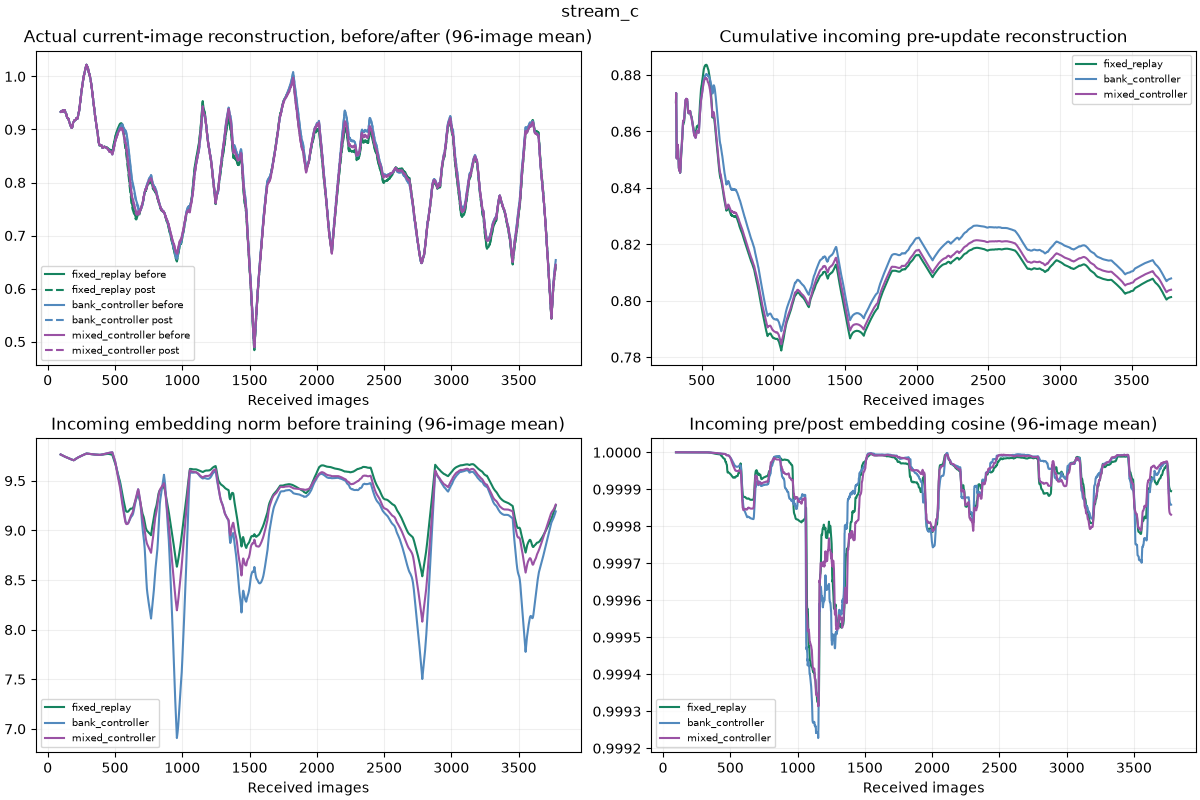

### Retained and recent population health
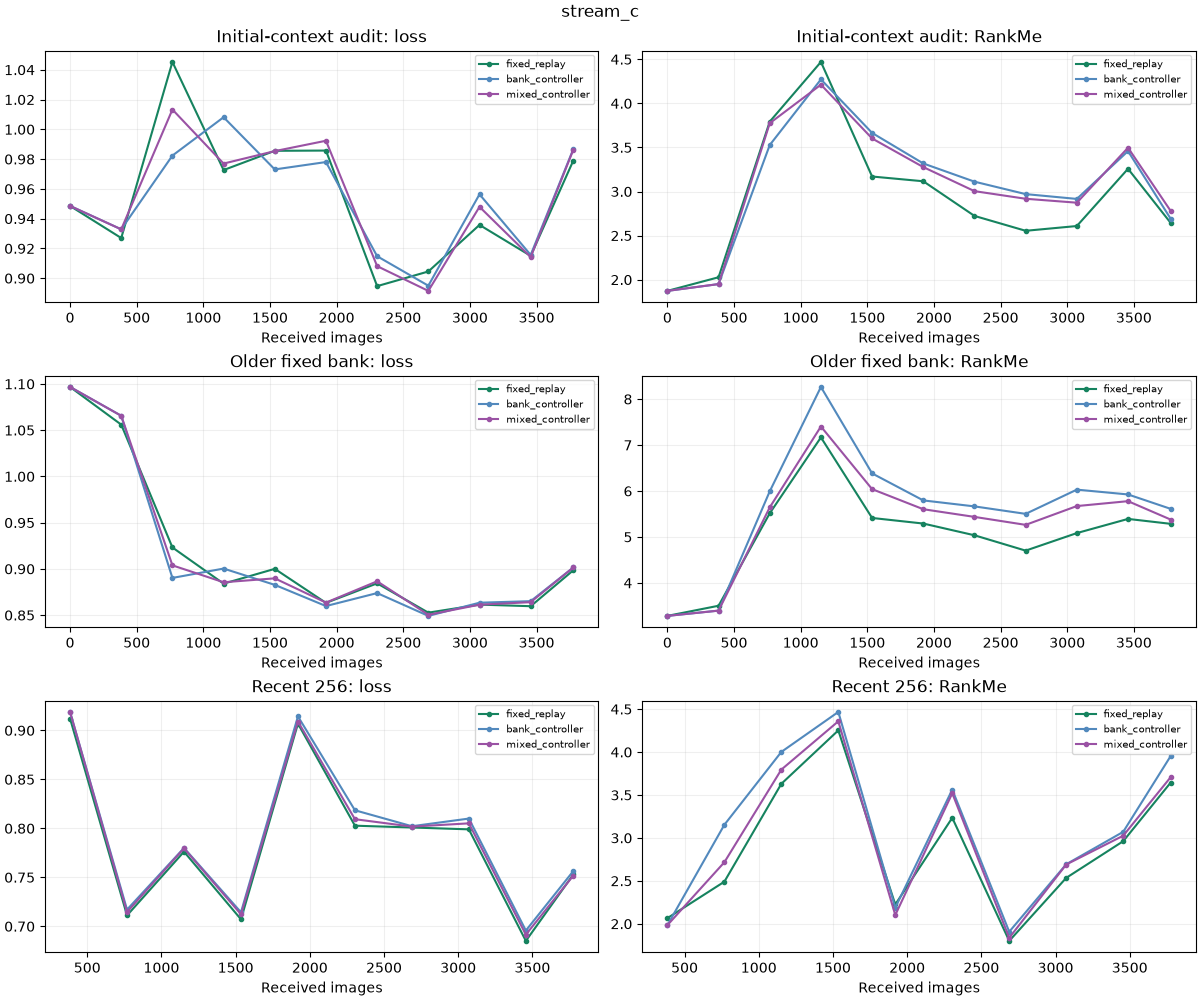

### Actual controller health, actions and LR dose
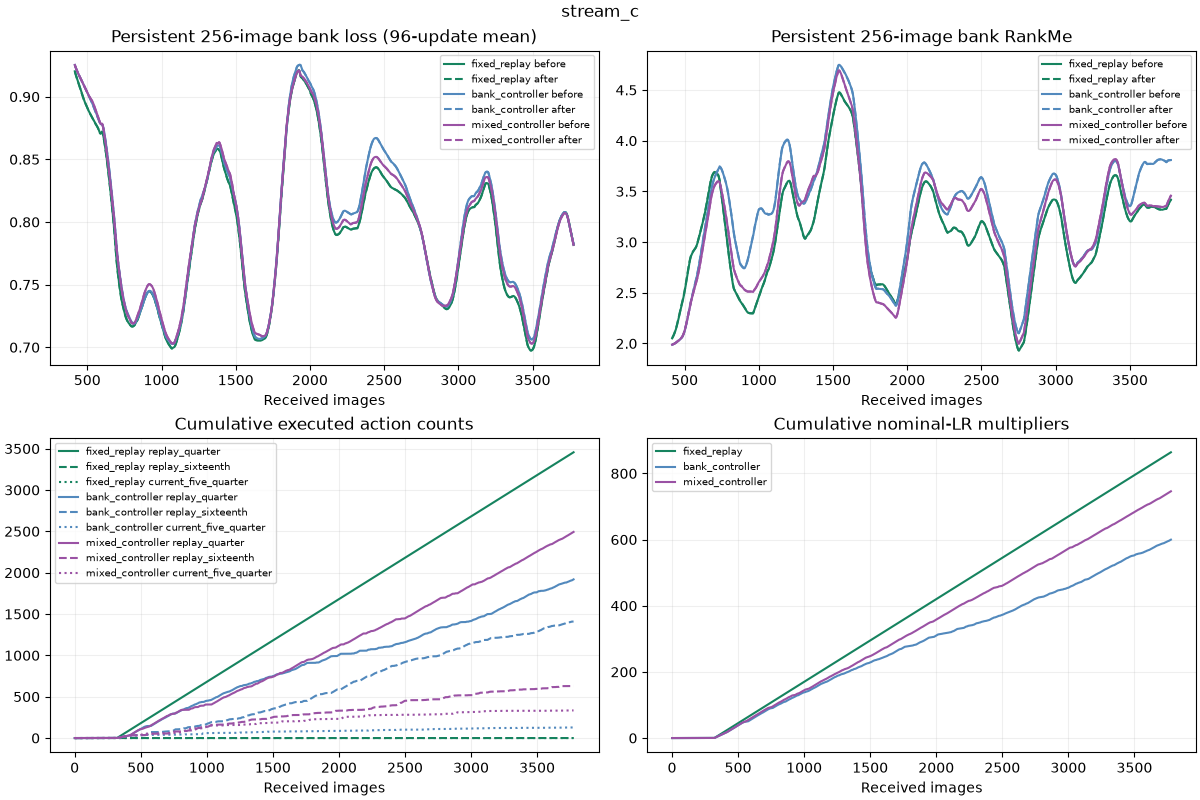

### Persistent image histories and membership effects
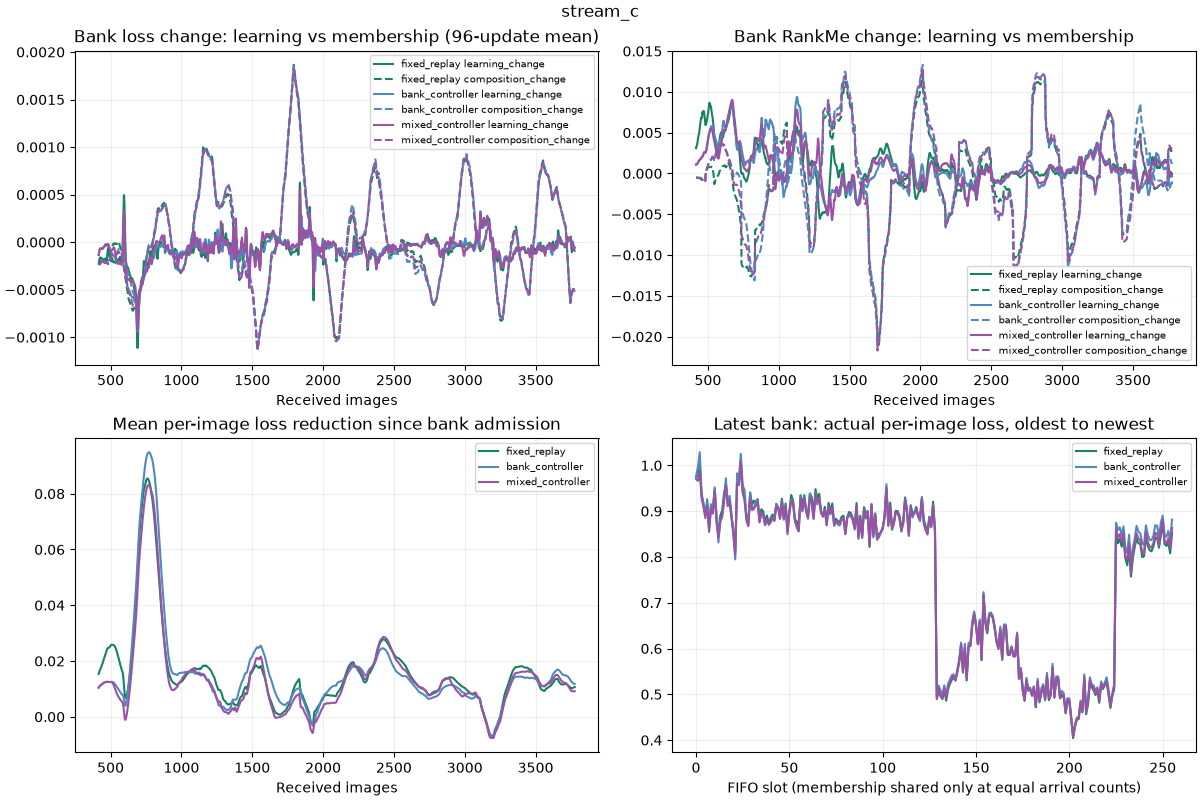

### stream_a: incoming (completed)
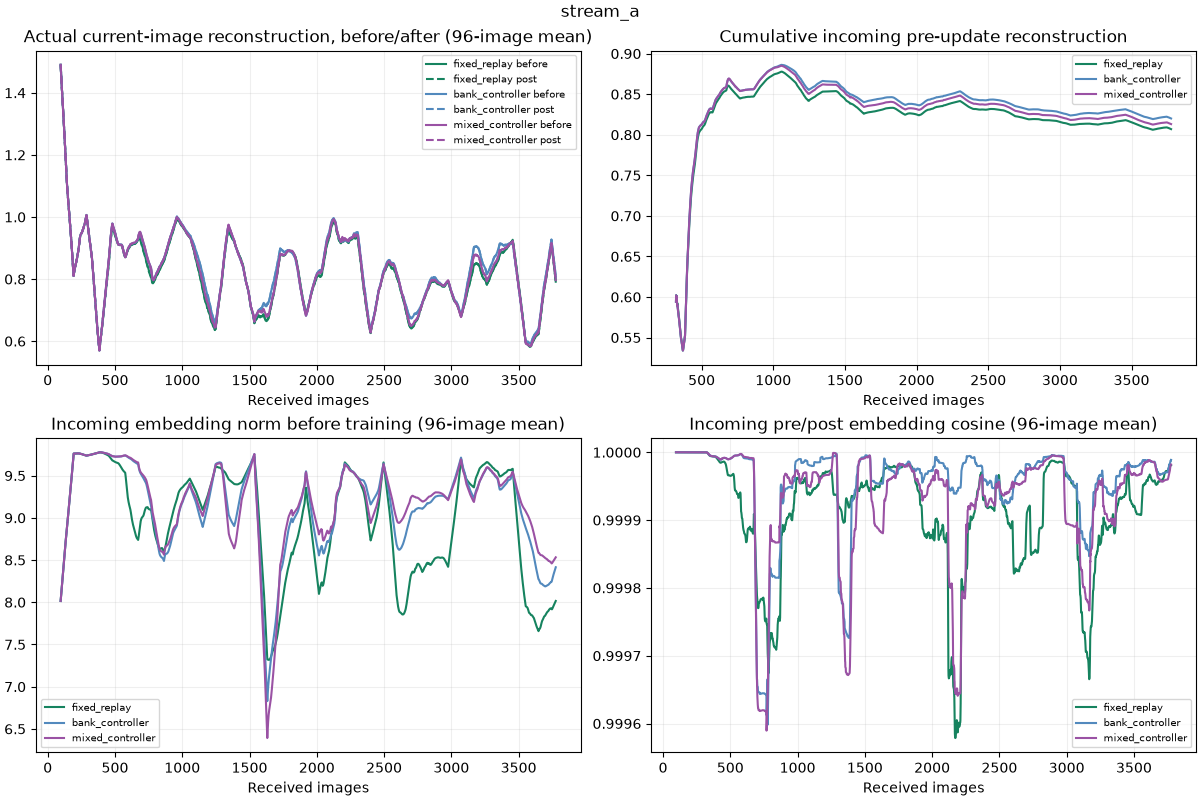

### stream_a: audits (completed)
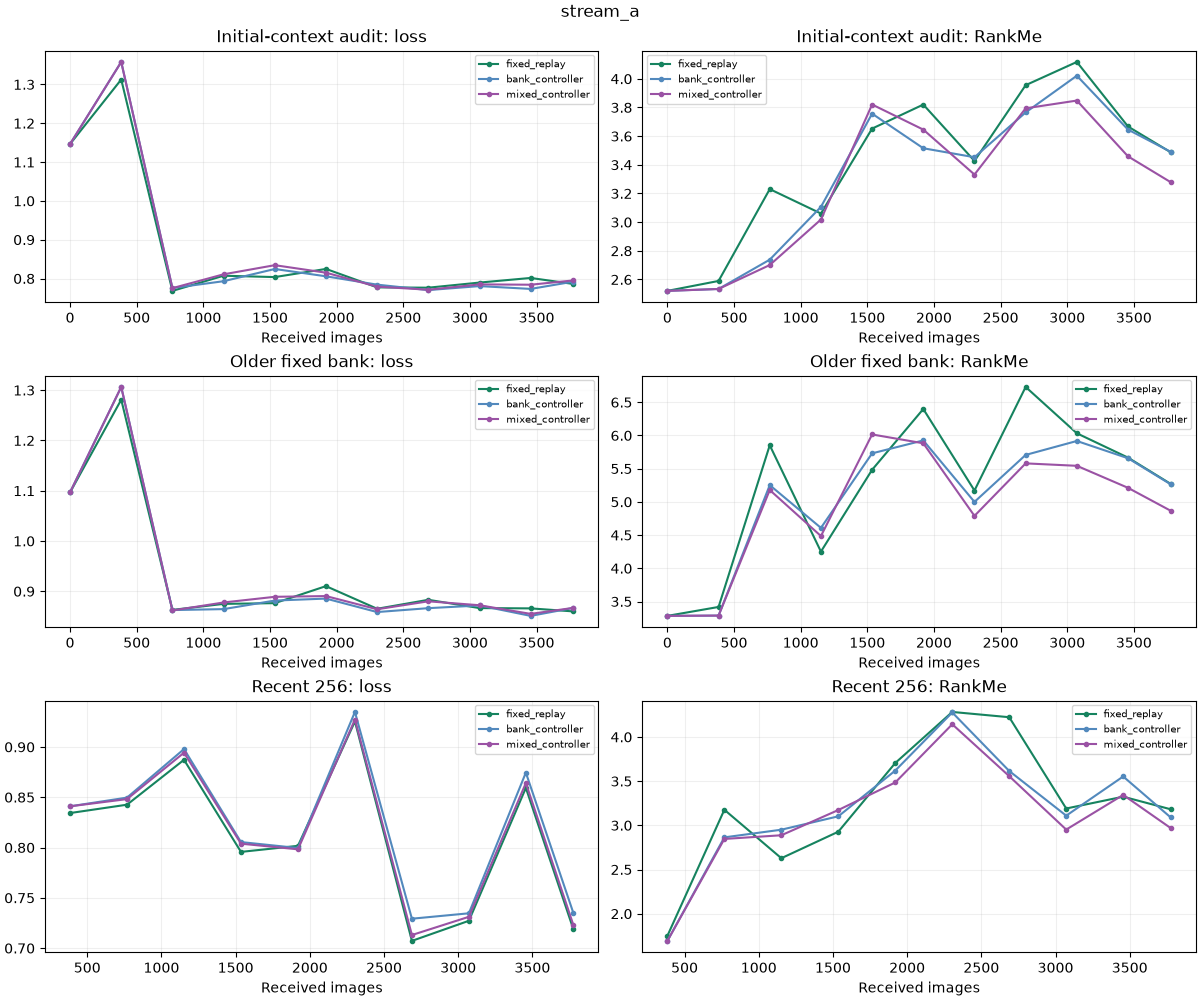

### stream_a: control (completed)
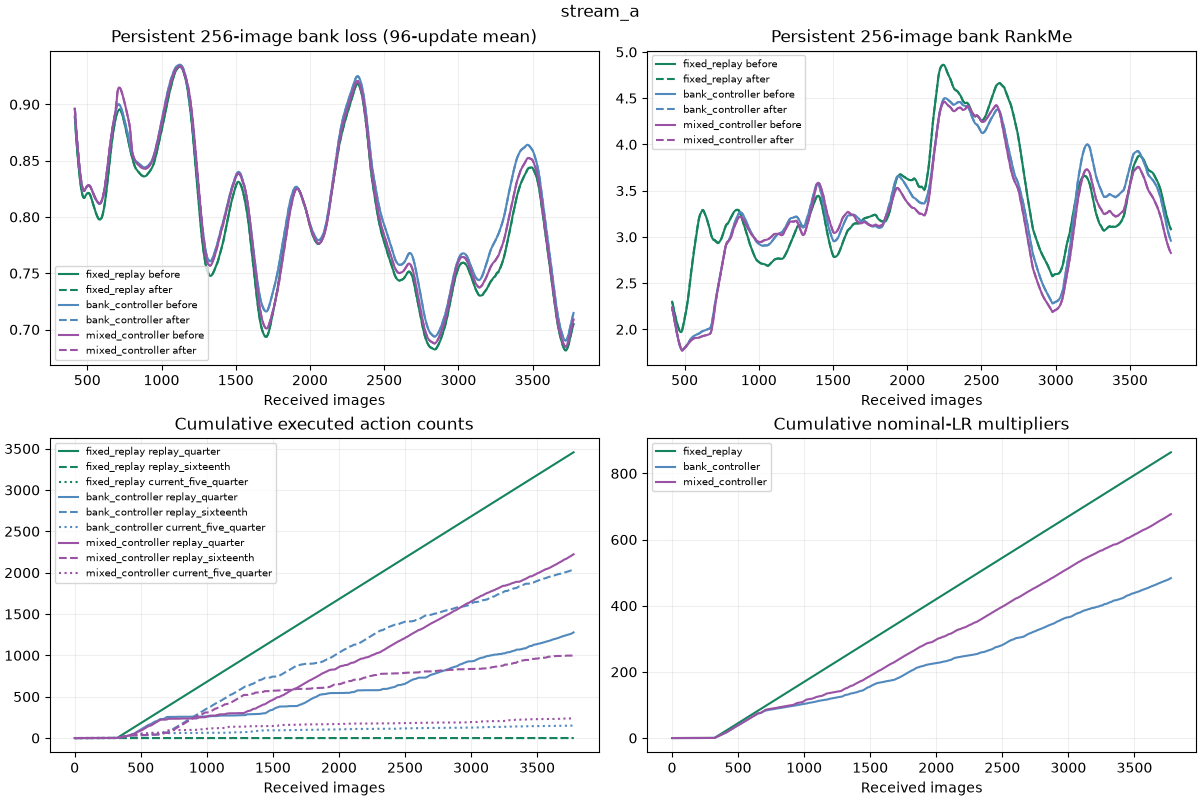

### stream_a: membership (completed)
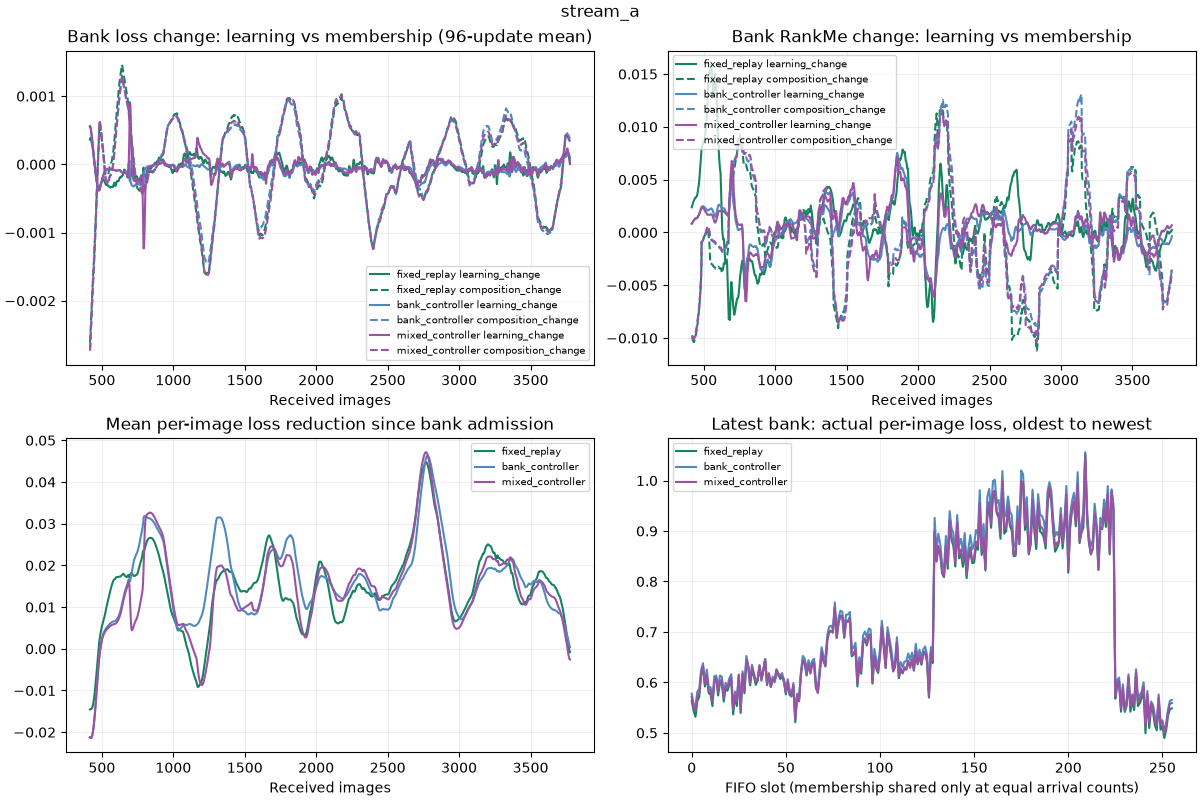

### stream_b: incoming (completed)
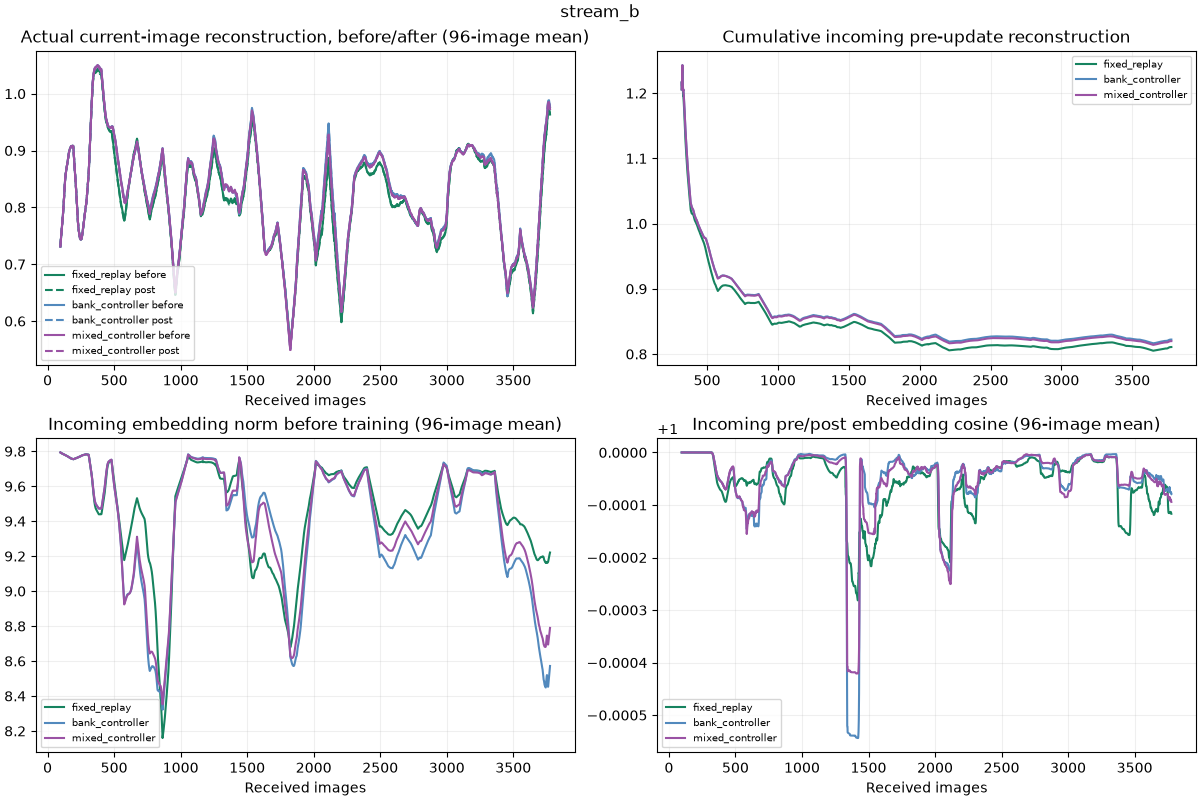

### stream_b: audits (completed)
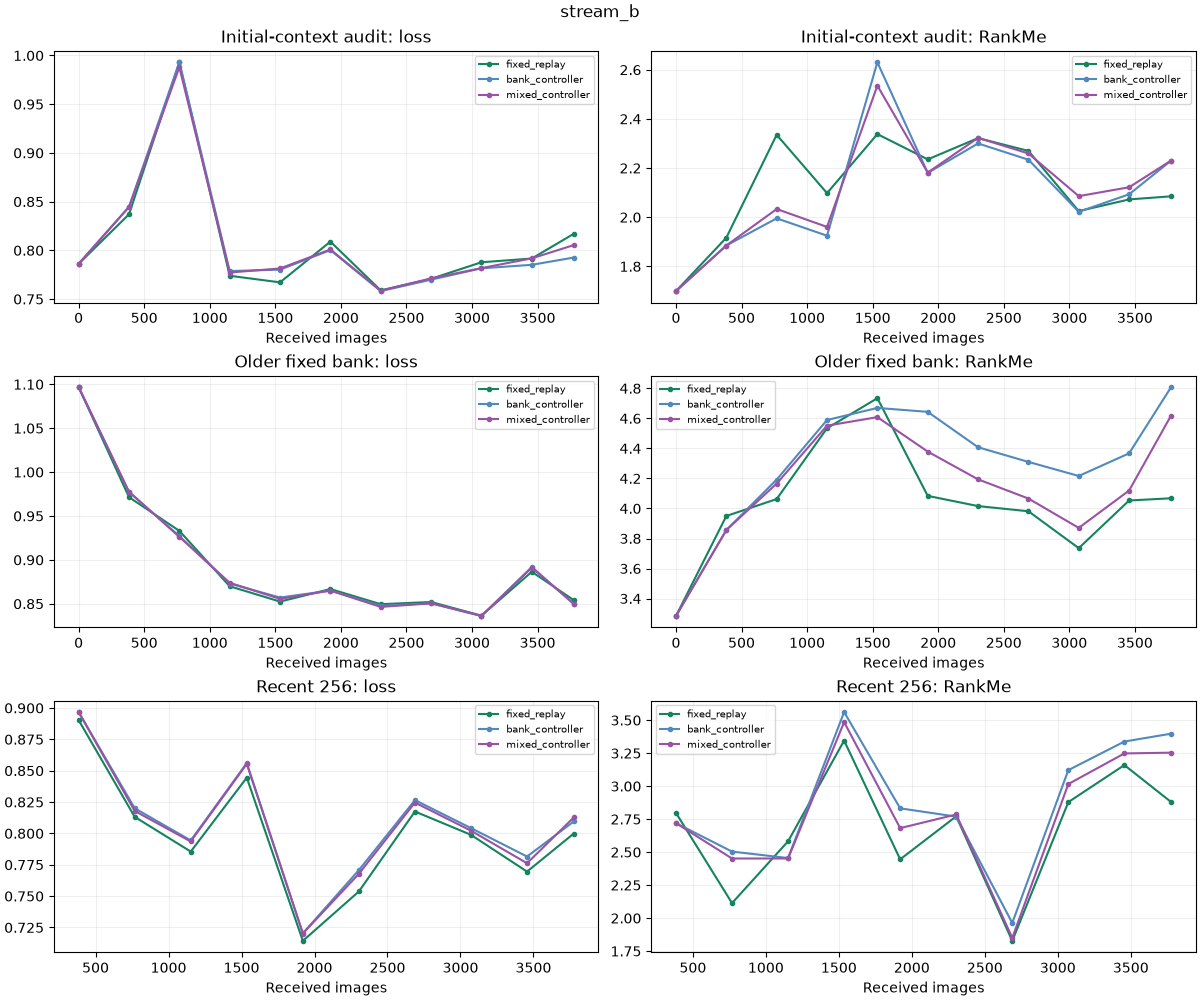

### stream_b: control (completed)
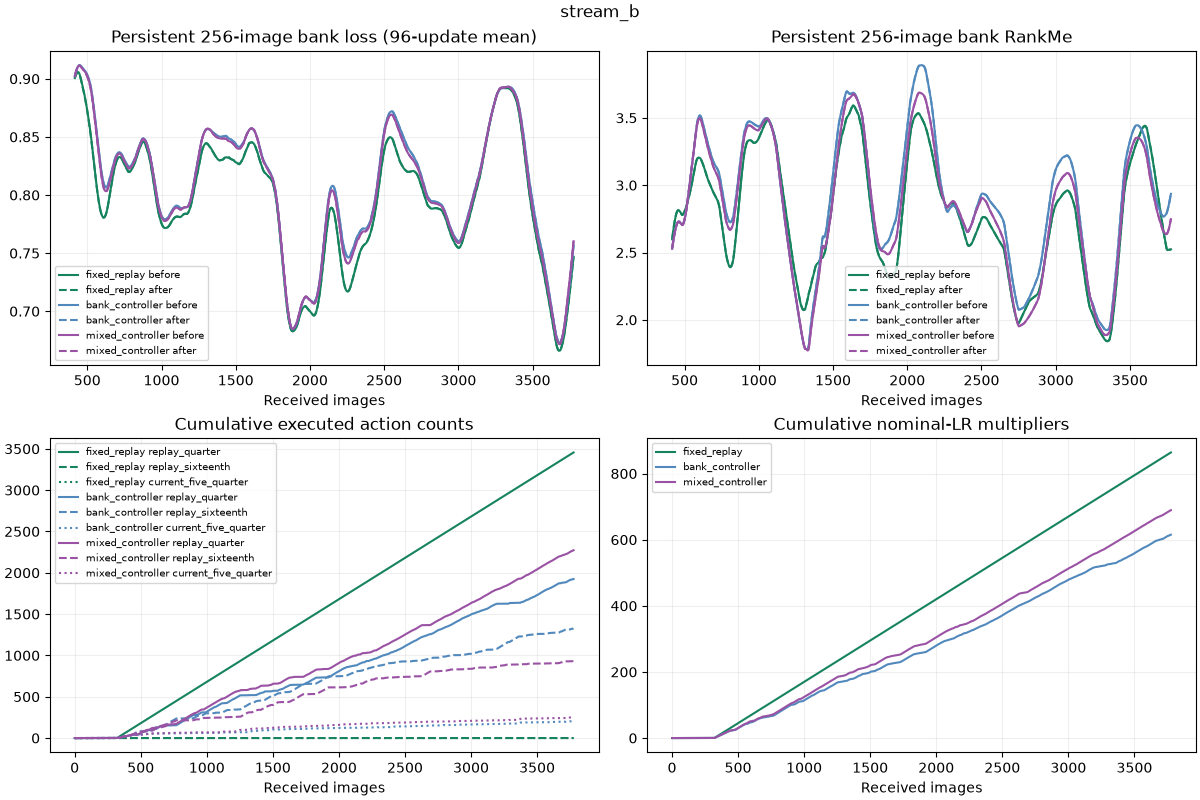

### stream_b: membership (completed)
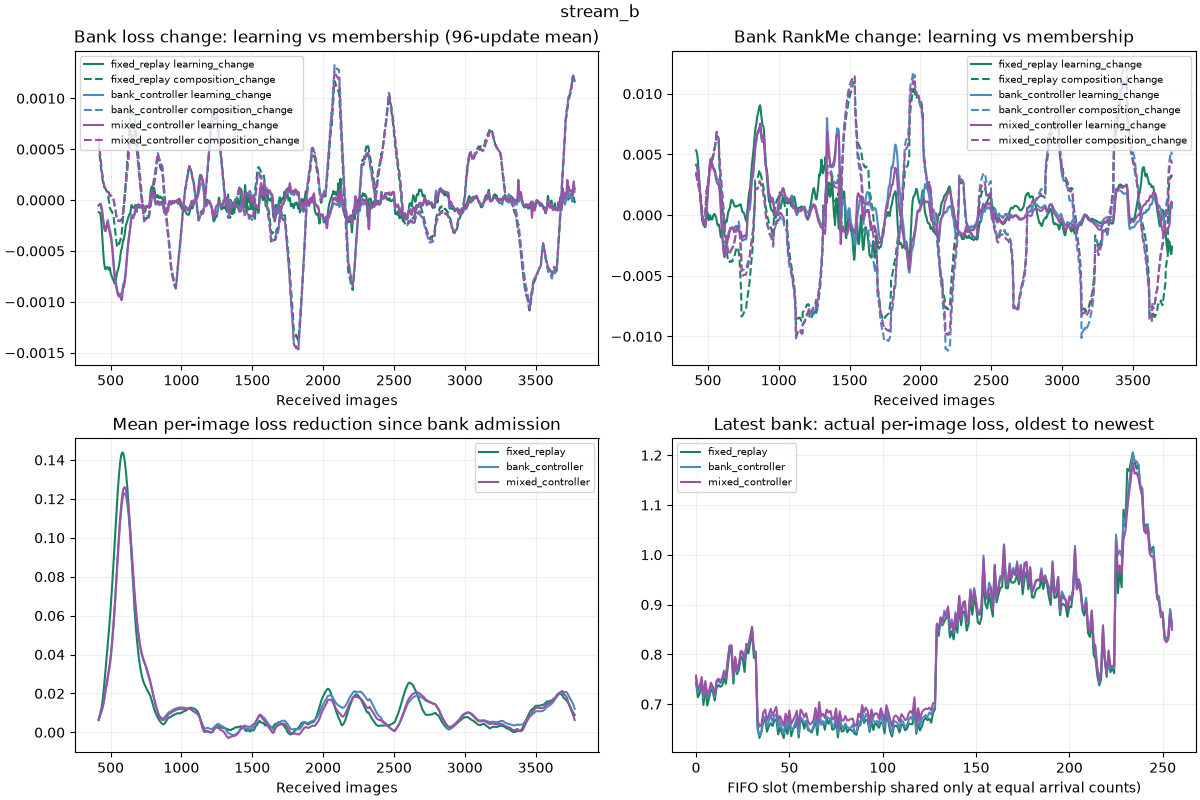